# DATA-445: Homework Assignment 7

**Instructions**

- This homework assignment is worth **103** points.
- Please submit a **.ipynb** file to Blackboard.
- **Please strive for clarity and organization.**
- **AI usage**:
  - AI use is strictly **prohibited** for conceptual exercises.
  - For applied (Python) exercises, you may use AI exclusively for **debugging**. Do not use AI to generate answers.
- **Due Date: November 6, 2026, by 11:59 PM.**

## Exercise 1 (5 points)

Why feature scaling is important for the $k$-means algorithm? Be specific.

**Answer:** feature scaling is important for kmeans because kmeans uses euclidean distance to cluster. so if the features are not scaled then some features will have more influence because of there large scale compared to others.

## Exercise 2 (5 points)

How can clustering be used to improve the performance of a linear model?

(a) Creating different models for different cluster groups.

(b) Creating an input feature for cluster ids as dummy variables.

(c) Creating an input feature for cluster centroids as a continuous variable.

(d) Creating an input feature for cluster size as a continuous variable.

(e) All of the above.

(f) None of the above.

**Answer:** (e)

## Exercise 3 (5 points)

What are the risks of initial random cluster centroids assignments in $k$-means? Be specific.

**Answer:** the risks of initial random cluster centroids assignments is that the initial cluster is not guranteed to choose the best initial cluster so it could not always converge to the best outcome.

## Exercise 4 (5 points)

Spectral clustering and $k$-means make different assumptions about the shape of the clusters. Explain, in your own words, how spectral clustering constructs clusters (mention the similarity graph and the graph Laplacian) and describe a type of dataset for which spectral clustering would be expected to outperform $k$-means. Be specific.

**Answer:** spectral clustering creates a similarity graph and then graphs laplacian which it uses the eigenvectors to transform the features which helps find clusters that are non spherical or irregular shaped.

## Exercise 5 (5 points)

In $k$-means, every observation is assigned to exactly one cluster (a hard assignment). Explain how fuzzy c-means differs from $k$-means in terms of cluster membership, and describe what role the fuzziness parameter $m$ plays in the algorithm. Be specific.

**Answer:** fuzzy c means gives the degree of membership for the clusters and the m parameter choses how strict the assigment is.

## Exercise 6

Consider the `Mall_Customers.csv` data file. This file contains the basic information (ID, age, gender, income, spending score) about mall customers in the US. **In Python**, answer the following:

### (a) (5 points)

Using the `pandas` library, read the csv data file and create a data-frame called `customers`. Remove the observations with missing values (if there are missing values).

In [48]:
# Your code here
import pandas as pd

customers = pd.read_csv('Mall_Customers.csv')
customers.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [49]:
customers.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

### (b) (8 points)

Using the appropriate Python commands, put `Gender`, `Age` and `Annual Income (k$)` in the same scale.

In [50]:
# Your code here
from sklearn.preprocessing import StandardScaler

customers_original = pd.read_csv('Mall_Customers.csv')
customers_original['Gender'] = customers_original['Gender'].map({'Male': 0, 'Female': 1})
customers.drop(columns=['CustomerID','Spending Score (1-100)'], inplace=True)
customers['Gender'] = customers['Gender'].map({'Male': 0, 'Female': 1})
scaler = StandardScaler()
customers[[  'Gender', 'Age', 'Annual Income (k$)']] = scaler.fit_transform(customers[['Gender', 'Age', 'Annual Income (k$)']])
customers.head()


,Gender,Age,Annual Income (k$)
0,-1.128152,-1.424569,-1.738999
1,-1.128152,-1.281035,-1.738999
2,0.886405,-1.352802,-1.700830
3,0.886405,-1.137502,-1.700830
4,0.886405,-0.563369,-1.662660


### (c) (30 points)

Because you are not familiar enough with buying patterns in malls, estimate the number of clusters for this dataset using the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores. Do the following:

- Using `Gender`, `Age` and `Annual Income (k$)` cluster that data into clusters ($k = 2, 3, \ldots, 9, 10$). Use `n_init = 20`.
- For each clustering result, compute the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores.
- Visualize the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores.
- Estimate the number of clusters.

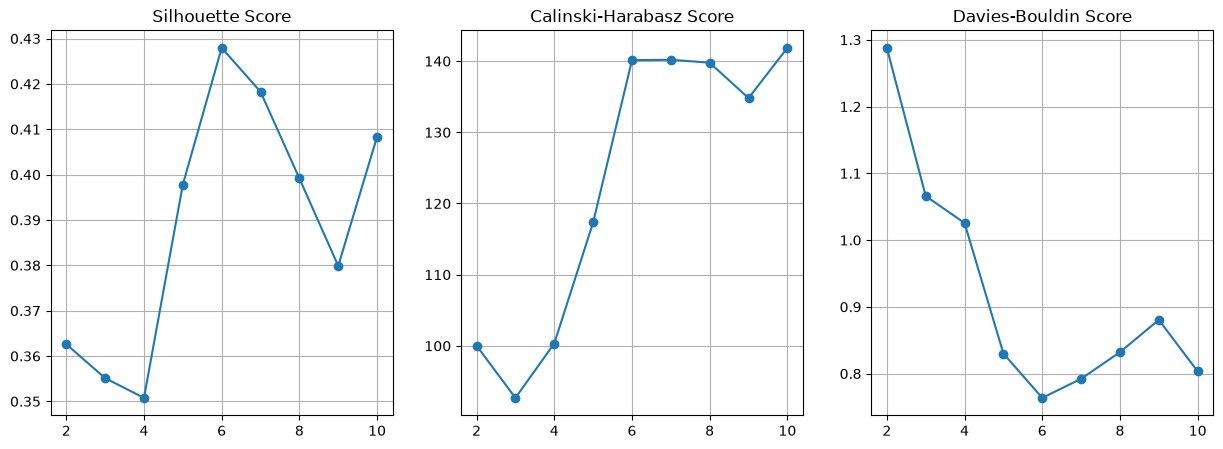

In [51]:
# Your code here
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import davies_bouldin_score
import matplotlib.pyplot as plt

ks = range(2, 11)
silhouette_scores = []
calinski_scores = []
davies_scores = []

for k in ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
    kmeans.fit(customers)
    labels = kmeans.labels_
    
    silhouette_scores.append(silhouette_score(customers, labels))
    calinski_scores.append(calinski_harabasz_score(customers, labels))
    davies_scores.append(davies_bouldin_score(customers, labels))
    
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot(ks, silhouette_scores, marker='o')
plt.title('Silhouette Score')
plt.grid(True)
plt.subplot(1, 3, 2)
plt.plot(ks, calinski_scores, marker='o')
plt.title('Calinski-Harabasz Score')
plt.grid(True)
plt.subplot(1, 3, 3)
plt.plot(ks, davies_scores, marker='o')
plt.title('Davies-Bouldin Score')
plt.grid(True)
plt.show()

**Answer:** for the silhouette score it is 6 clusters, for the calinski it is 10 clusters and for the davies bouldin it is 2 clusters. so I am leaning towards 6 clusters.

### (d) (8 points)

Using the results from part (c), cluster the data into that number of clusters (use `n_init = 20`).

In [52]:
# Your code here

kmeans = KMeans(n_clusters=6, random_state=42, n_init=20)
kmeans.fit(customers)
customers['Cluster'] = kmeans.labels_
customers.head()

,Gender,Age,Annual Income (k$),Cluster
0,-1.128152,-1.424569,-1.738999,3
1,-1.128152,-1.281035,-1.738999,3
2,0.886405,-1.352802,-1.700830,2
3,0.886405,-1.137502,-1.700830,2
4,0.886405,-0.563369,-1.662660,2


In [40]:
customers_original.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40


### (e) (7 points)

Describe each of the clusters. Does the clustering results make sense? If not, suggest how you would improve this analysis.

In [39]:
# Your code here

customers_original['Cluster'] = kmeans.labels_
customers_original.groupby('Cluster').mean()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,,
0,79.250000,0.0,58.821429,51.678571,38.035714
1,161.300000,1.0,35.600000,86.400000,56.050000
2,50.081081,1.0,26.891892,38.594595,56.378378
3,51.666667,0.0,25.666667,39.291667,59.125000
4,74.914286,1.0,52.800000,50.057143,41.228571
5,158.722222,0.0,34.444444,85.722222,49.583333


**Answer:** the female clusters are in different age ranges and income varies also. the spending score does not raise in correlation with there age and income though. the thing that does not make sense is that clusters 2 and 3 are very similar so maybe the amount of clusters could be adjusted. spending score when of younger age is higher than the rest.

## Exercise 7 (20 points)

Consider again the `Mall_Customers.csv` data file. In this exercise you will use **DBSCAN** to find groups of customers based on `Annual Income (k$)` and `Spending Score (1-100)`, and to identify customers that do not belong to any group. **In Python**, answer the following:

### (a) (4 points)

Read the csv data file into a data-frame called `mall`, and standardize `Annual Income (k$)` and `Spending Score (1-100)` (mean 0 and standard deviation 1). Explain why scaling matters for DBSCAN.

In [53]:
# Your code here
mall = pd.read_csv('Mall_Customers.csv')

scaler = StandardScaler()

mall_scale = scaler.fit_transform(mall[['Annual Income (k$)', 'Spending Score (1-100)']])

**Answer:** dbscans uses distance to identify clusters and density so the scale will affect the result.

### (b) (6 points)

Set `min_samples = 5`. Choose a value for `eps` using a $k$-distance plot: for each observation compute the distance to its 5th nearest neighbor (the observation itself counts as its own first neighbor in `sklearn`), sort these distances, and plot them. Which value of `eps` do you choose and why?

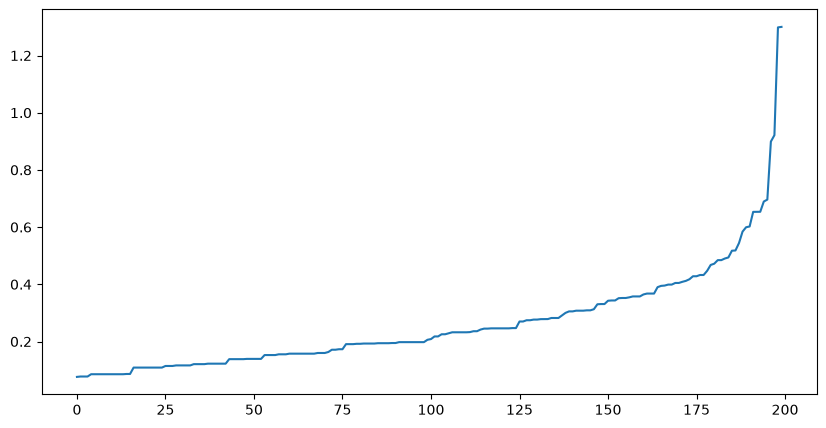

In [ ]:
# Your code here
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import numpy as np

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(mall_scale)
neighbors_distances, neighbors_indices = neighbors_fit.kneighbors(mall_scale)

distances = np.sort(neighbors_distances[:, 4], axis=0)
plt.figure(figsize=(10, 5))
plt.plot(distances)

**Answer:** like .5 because that is where the distance steeply increases

### (c) (5 points)

Fit DBSCAN with `min_samples = 5` and your chosen `eps`. Report the number of clusters found, the size of each cluster, and the number of observations labeled as noise. Then visualize the result with a scatter plot of the two variables, coloring the points by cluster label and showing noise points in a distinct color.

Number of clusters found: 2
Number of noise points: 8


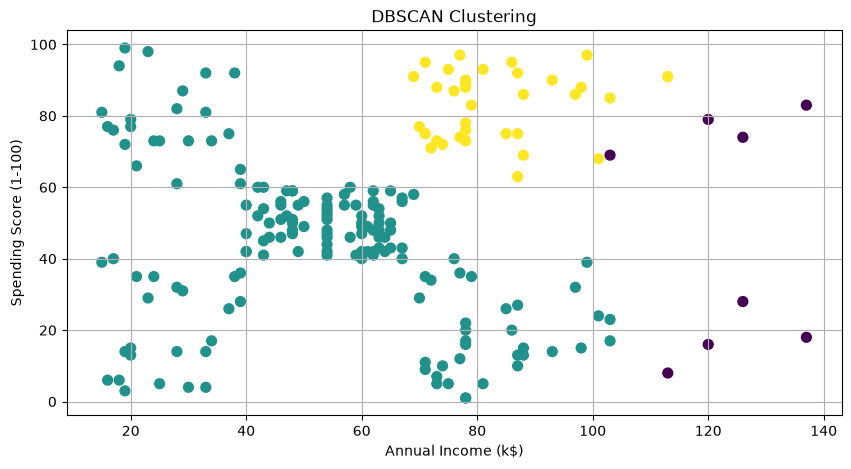

In [60]:
# Your code here
dbscan = DBSCAN(eps=0.5, min_samples=5)

labels = dbscan.fit_predict(mall_scale)

mall['DBSCAN_Cluster'] = labels 

print("Number of clusters found:", len(set(labels)) - (1 if -1 in labels else 0))
print("Number of noise points:", list(labels).count(-1))

plt.figure(figsize=(10, 5))
plt.scatter(mall['Annual Income (k$)'], mall['Spending Score (1-100)'], c=mall['DBSCAN_Cluster'], cmap='viridis', s=50)
plt.title('DBSCAN Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True)
plt.show()


### (d) (5 points)

Describe each cluster (average income and spending score) and the noise points. Then explain what happens to the number of clusters and the number of noise points if you (i) decrease `eps` or (ii) increase `min_samples`. Support your answer by trying at least two different settings. How does DBSCAN compare to $k$-means for this data?

In [62]:
# Your code here
mall.groupby('DBSCAN_Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean()

,Annual Income (k$),Spending Score (1-100)
DBSCAN_Cluster,,
-1,122.750000,46.875000
0,52.490446,43.101911
1,82.542857,82.800000


**Answer:** the noise has high annual income. the first cluster has lower income and spending while the other has higher income and spending.

Number of clusters found: 4
Number of noise points: 15


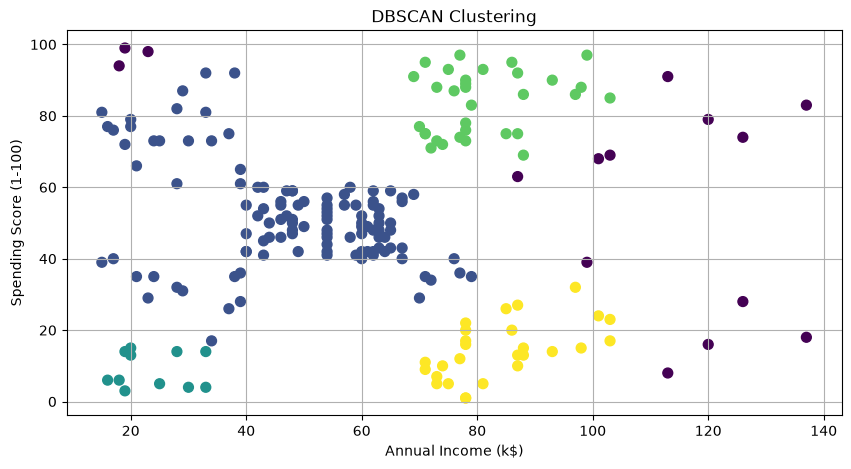

In [64]:
dbscan = DBSCAN(eps=0.4, min_samples=5)

labels = dbscan.fit_predict(mall_scale)

mall['DBSCAN_Cluster'] = labels 

print("Number of clusters found:", len(set(labels)) - (1 if -1 in labels else 0))
print("Number of noise points:", list(labels).count(-1))

plt.figure(figsize=(10, 5))
plt.scatter(mall['Annual Income (k$)'], mall['Spending Score (1-100)'], c=mall['DBSCAN_Cluster'], cmap='viridis', s=50)
plt.title('DBSCAN Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True)
plt.show()


at .4 eps the amount of clusters and noise went up

Number of clusters found: 2
Number of noise points: 12


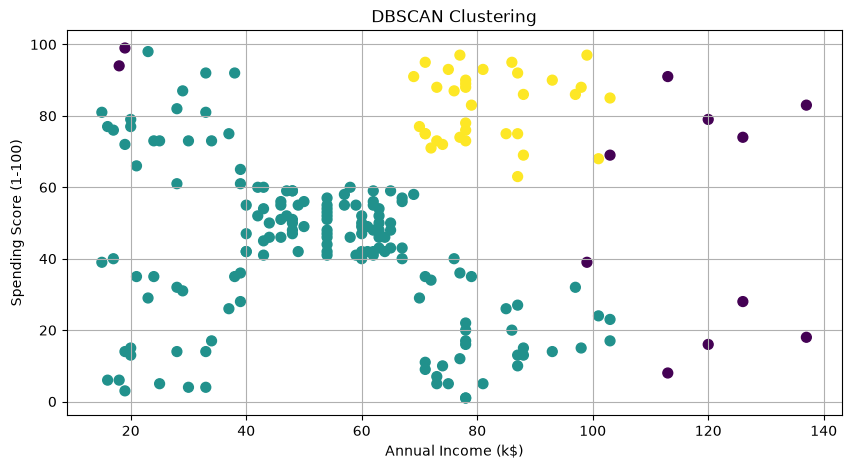

In [65]:
dbscan = DBSCAN(eps=0.5, min_samples=7)

labels = dbscan.fit_predict(mall_scale)

mall['DBSCAN_Cluster'] = labels 

print("Number of clusters found:", len(set(labels)) - (1 if -1 in labels else 0))
print("Number of noise points:", list(labels).count(-1))

plt.figure(figsize=(10, 5))
plt.scatter(mall['Annual Income (k$)'], mall['Spending Score (1-100)'], c=mall['DBSCAN_Cluster'], cmap='viridis', s=50)
plt.title('DBSCAN Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True)
plt.show()


when min samples went up only the noise increased

i think k means did better than dbscans in identifing the clusters.